 # Random behavior of assets: Based on Chapter 3 Wilmott's book

Import libraries: for this chapter I am using yfinance to obtain historic data

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
stock_keywords= ['SU.PA', 'msft', 'SIE.DE', 'aapl', 'goog']
timeframe= "5y"

Read csv files and transform them to pandas dataframes

In [4]:
def create_pandas_from_csv(list_of_keywords, timeframe="1y"):
    dataframes_list=[]
    for key in list_of_keywords:
        temp_df= pd.read_csv(key+"_"+timeframe+".csv")
        dataframes_list.append(temp_df)
    return(dataframes_list)

For stocks we focus on closing

In [5]:
atclosing=[create_pandas_from_csv(stock_keywords, timeframe=timeframe)[i].Close for i in range(len(stock_keywords))]

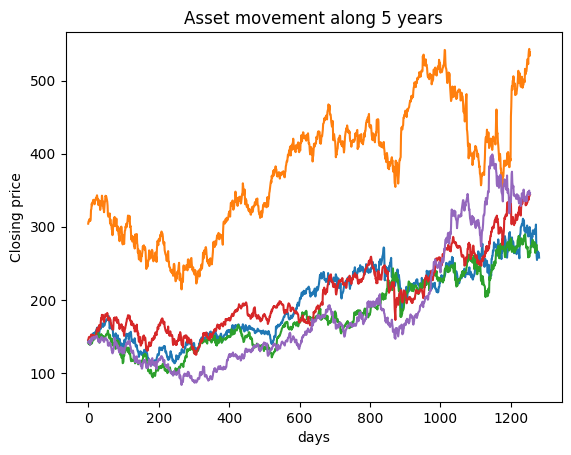

In [6]:
for i in range(len(stock_keywords)):
    plt.plot(atclosing[i])
plt.xlabel('days')
plt.ylabel('Closing price')
plt.title('Asset movement along 5 years')
plt.show()

Calculate simple returns

In [7]:
data_np=[create_pandas_from_csv(stock_keywords, timeframe=timeframe)[i].Close.to_numpy() for i in range(len(stock_keywords))]

In [8]:
def simple_returns(vals_at_closing):
    rets=[]
    for i in range(len(vals_at_closing)-1):
        rets.append((vals_at_closing[i+1]-vals_at_closing[i])/vals_at_closing[i])
        rets_np=np.array(rets)
    return(rets)

In [9]:
rets_simple=[simple_returns(data_np[i]) for i in range(len(stock_keywords)) ]

In [10]:
def simple_returns_plot(data,pos, keywords):
    plt.scatter(range(len(data[pos])),data[pos],
            s = 1, # marker size
           )
    plt.xlabel('days'+' ('+keywords[pos]+')')
    plt.ylabel('Simple returns')
    plt.title('Noisy returns')
    plt.show()

Plots "look" like noise. For example,MSFT

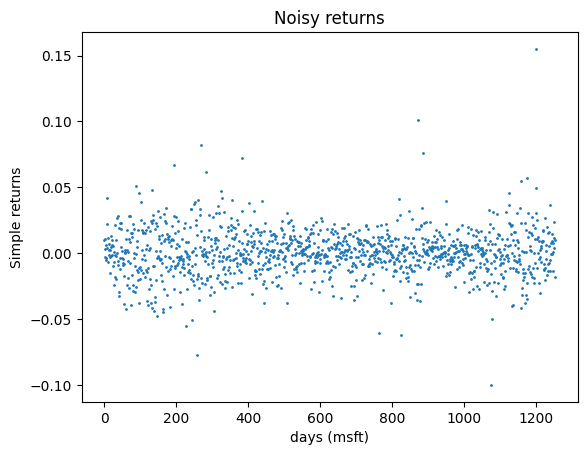

In [11]:
simple_returns_plot(rets_simple,1,stock_keywords)

Let us now compare returns against normal distribution.  We will adjust the data to compare against probability density function for the standardized Normal distribution function


In [12]:
def normdata(data):
    np_mean=np.mean(data)
    np_std=np.std(data)
    return(data-np_mean)/np_std

In [13]:
def plot_with_normal(data,keyword):
    z= normdata(data)
    x = np.linspace(-10, 10, 100)
    normalizedpdf=1/(np.sqrt(2*np.pi))*np.exp(-(x)**2/2)
    plt.plot(x,normalizedpdf)
    plt.hist(z, bins=100, density=True)
    plt.title('Normalized histogram'+' ('+keyword+')')
    plt.show()

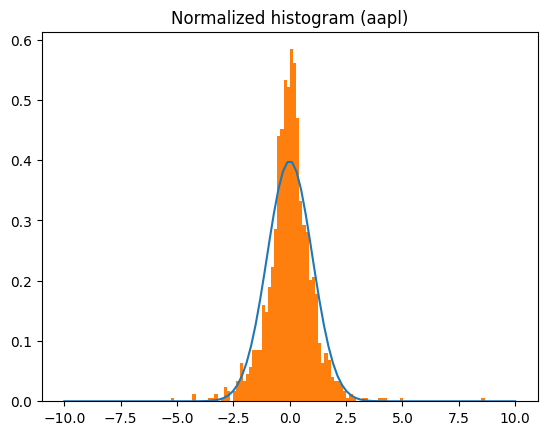

In [14]:
plot_with_normal(rets_simple[3], stock_keywords[3])

## Estimate volatility

$$ volatility=  \sqrt{\frac {1}{(M-1)\delta t} \sum_{i=1}^M (R_i-\bar{R})^2} $$

In [15]:
def simple_volatility(array_returns, delta_t=1/252):
    mean=np.mean(array_returns)
    volatility=np.sqrt((1/(len(array_returns)-1)/delta_t)*np.sum((array_returns-mean)**2))
    return 100*volatility

In [16]:
print(simple_volatility(rets_simple[0][1:252]))

32.81082610758658


$$ volatility=  \sqrt{\frac {1}{(M-1)\delta t} \sum_{i=1}^M (log\ S(t_i)-log\ S(t_{i-1}))^2} $$

In [17]:
def simple_log_volatility(array_series, delta_t=1/252):
    rets=[]
    for i in range(len(array_series)-1):
        rets.append((np.log(array_series[i+1])-np.log(array_series[i]))**2)
        volatility=np.sqrt(1/(len(array_series)-1)/delta_t*np.array(np.sum(rets)))
    return 100*volatility

In [18]:
print(simple_log_volatility(data_np[0][1:252]))

32.74310933726392


## Simplest random walk

Finally we are going to reproduce the random walk on the spreadsheet that Wilmott does but we will use Python instead

$$ S_{i+1}= S_i (1+\mu \delta t+ \sigma \phi \delta t^{1/2}) $$

In [19]:
#constants
asset_price=100
drift=0.15
volatility=0.25
timestep=0.01

In [36]:
def random_walk_simple(initial_asset_price, number_of_steps, drift, volatility, timestep):
    time=0
    times_history=np.array([time])
    asset_price=initial_asset_price
    asset_prices_history=np.array([asset_price])
    #Unvectorized approach
    for i in range(number_of_steps):
        time = time+timestep
        times_history= np.append(times_history, [time])
        asset_price=asset_price*(1+drift*timestep+volatility*np.sqrt(timestep)*(np.random.standard_normal()))
        asset_prices_history= np.append(asset_prices_history, [asset_price])
    return np.array([times_history,asset_prices_history])

In [37]:
tis=random_walk_simple(initial_asset_price=asset_price, number_of_steps=50, drift=drift, volatility=volatility, timestep=timestep)

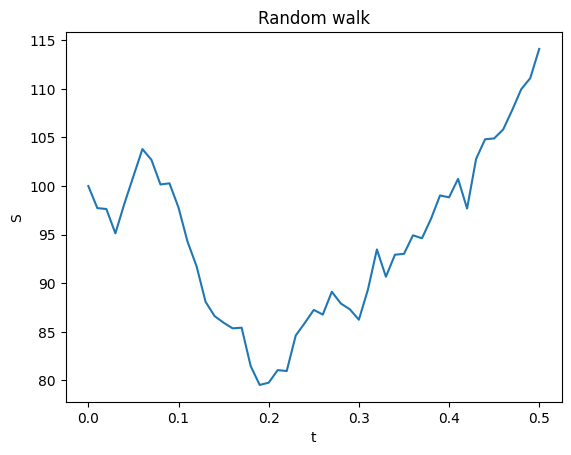

In [38]:
plt.plot(tis[0],tis[1])
plt.xlabel('t')
plt.ylabel('S')
plt.title('Random walk')
plt.show()